# Results: Tomato disease classification (lab → field)

This notebook **only displays results**; all training and evaluation code lives in `src/train.py`.
It reads what the training runs wrote to `outputs/`:

- `outputs/results.csv`: one row per (run, eval set)
- `outputs/runs/<run_name>/`: training history, per-class metrics, confusion matrices

**How to use:** train runs first (see the README, or the optional cell below), then *Run All*.
New runs show up automatically. Figures are also saved to `reports/figures/` for the write-up.

Eval sets: `plantvillage_test` (lab images, same distribution as training),
`plantdoc_field` (all real-world field images), `plantdoc_official_test` (PlantDoc's official 68-image test subset).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap

from src.prepare import LABELS  # the 8 class names, in label-index order
%matplotlib inline

OUTPUTS = Path("outputs")
RUNS = OUTPUTS / "runs"
FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Colours: one fixed colour per dataset, used in every chart.
PV_COLOR, PD_COLOR = "#2a78d6", "#eb6834"   # PlantVillage = blue, PlantDoc = orange
RUN_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # one per run, fixed order
MUTED = "#8a8984"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ad", "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
})
pd.set_option("display.width", 200)

### Optional: run experiments from here
Leave `RUN = False` to just view existing results. Training takes ~30 min per CNN run on a laptop.

In [2]:
RUN = False
if RUN:
    !python -m src.train --config configs/baseline_majority.yaml
    !python -m src.train --config configs/E1.yaml --seed 0
    !python -m src.train --config configs/E2.yaml --seed 0

## 1. Dataset
Images per class in each split (from `data/manifest.csv`, built once by `src/prepare.py`).
PlantDoc is test-only; `excluded` are duplicates removed during preprocessing.

In [3]:
manifest = pd.read_csv("data/manifest.csv")
counts = pd.crosstab(manifest["label"], [manifest["source"], manifest["split"]]).reindex(LABELS)
counts.loc["TOTAL"] = counts.sum()
counts

source                 plantdoc            plantvillage             
split                  excluded field_test         test  train   val
label                                                               
bacterial_spot                5        105          212   1703   212
early_blight                  7         81          100    800   100
late_blight                   5        106          191   1527   191
leaf_mold                     1         90           96    760    96
septoria_leaf_spot           11        140          177   1417   177
mosaic_virus                  1         53           38    298    37
yellow_leaf_curl_virus        4         72          535   4286   536
healthy                       0         63          159   1273   159
TOTAL                        34        710         1508  12064  1508

## 2. Results table
One row per configuration. If a configuration was run with several seeds, numbers are the mean
(`seeds` column says how many). Macro-F1 is the main metric; the brackets are its 95% bootstrap confidence interval.

In [4]:
results = pd.read_csv(OUTPUTS / "results.csv")
results = results[~results["run_name"].str.startswith("debug_")]
results["cap"] = results["cap"].map(lambda c: "None" if pd.isna(c) else str(int(c)))

CONFIG = ["experiment", "model", "aug", "cap"]
EVAL_SETS = ["plantvillage_test", "plantdoc_field", "plantdoc_official_test"]

summary = (results.groupby(CONFIG + ["eval_set"], sort=False)
           .agg(seeds=("seed", "nunique"), accuracy=("accuracy", "mean"), macro_f1=("macro_f1", "mean"),
                macro_f1_std=("macro_f1", "std"), ci_low=("macro_f1_ci_low", "mean"),
                ci_high=("macro_f1_ci_high", "mean"), top2_acc=("top2_acc", "mean"), n_images=("n_images", "first"))
           .reset_index())
summary["config"] = summary["experiment"] + ": " + summary["model"] + ", aug=" + summary["aug"] + ", cap=" + summary["cap"]
# Baseline first, then experiments in order (E1, E2, ...).
configs = sorted(dict.fromkeys(summary["config"]), key=lambda c: (not c.startswith("baseline"), c))

def fmt(row):
    return f"{row.macro_f1:.3f} [{row.ci_low:.3f}, {row.ci_high:.3f}]"

table = summary.assign(**{"macro-F1 [95% CI]": summary.apply(fmt, axis=1), "acc": summary["accuracy"].round(3)})
table = table.pivot(index="config", columns="eval_set", values=["acc", "macro-F1 [95% CI]"])
table = table.reindex(index=configs, columns=EVAL_SETS, level=1)
table.insert(0, ("seeds", ""),summary.groupby("config")["seeds"].max())
table

seeds               acc                                           macro-F1 [95% CI]                                             
eval_set                                     plantvillage_test plantdoc_field plantdoc_official_test     plantvillage_test        plantdoc_field plantdoc_official_test
config                                                                                                                                                                 
baseline: majority, aug=none, cap=None     1             0.355          0.101                  0.088  0.065 [0.062, 0.069]  0.023 [0.019, 0.028]   0.020 [0.007, 0.035]
E1: simple_cnn, aug=none, cap=250          1             0.946          0.213                  0.294  0.938 [0.923, 0.952]  0.144 [0.122, 0.164]   0.223 [0.136, 0.292]

## 3. How much does performance drop on real-world images?
Lab (PlantVillage test) vs field (all PlantDoc images). The **drop** is lab score − field score;
the **domain gap** is the macro-F1 drop. Smaller is better: it means the model generalizes.

In [5]:
wide = summary.pivot(index="config", columns="eval_set", values=["accuracy", "macro_f1"]).reindex(configs)
drop = pd.DataFrame({
    "lab acc": wide[("accuracy", "plantvillage_test")],
    "field acc": wide[("accuracy", "plantdoc_field")],
    "acc drop": wide[("accuracy", "plantvillage_test")] - wide[("accuracy", "plantdoc_field")],
    "lab macro-F1": wide[("macro_f1", "plantvillage_test")],
    "field macro-F1": wide[("macro_f1", "plantdoc_field")],
    "domain gap (macro-F1 drop)": wide[("macro_f1", "plantvillage_test")] - wide[("macro_f1", "plantdoc_field")],
}).round(3)
drop

,lab acc,field acc,acc drop,lab macro-F1,field macro-F1,domain gap (macro-F1 drop)
config,,,,,,
"baseline: majority, aug=none, cap=None",0.355,0.101,0.253,0.065,0.023,0.042
"E1: simple_cnn, aug=none, cap=250",0.946,0.213,0.734,0.938,0.144,0.793


## 4. Lab vs field, per configuration
Error bars on macro-F1 are the 95% bootstrap CI. The dashed line is random guessing among 8 classes (1/8).

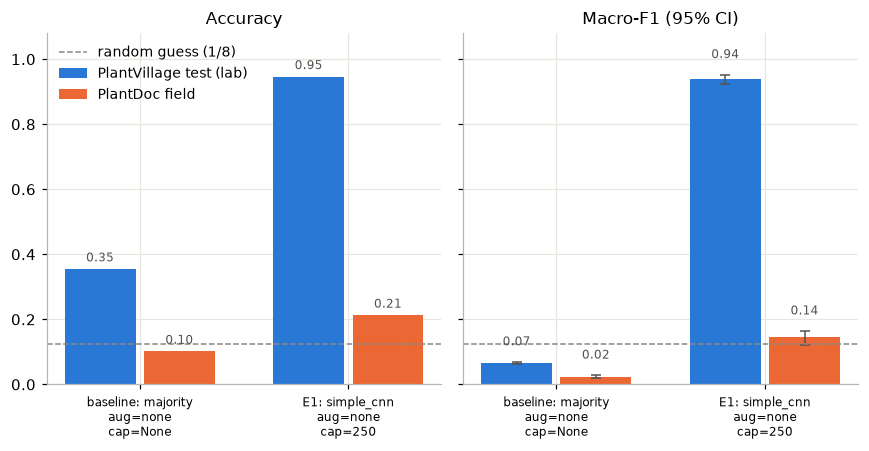

In [6]:
def lab_vs_field_chart(metric, ax, title):
    x = np.arange(len(configs))
    width = 0.38
    for offset, eval_set, color, name in [(-width / 2, "plantvillage_test", PV_COLOR, "PlantVillage test (lab)"),
                                          (width / 2, "plantdoc_field", PD_COLOR, "PlantDoc field")]:
        rows = summary[summary["eval_set"] == eval_set].set_index("config").reindex(configs)
        values = rows[metric].to_numpy()
        yerr = None
        if metric == "macro_f1":
            yerr = np.vstack([values - rows["ci_low"], rows["ci_high"] - values])
        bars = ax.bar(x + offset, values, width - 0.04, color=color, label=name, yerr=yerr,
                      error_kw={"elinewidth": 1, "capsize": 3, "ecolor": "#52514e"})
        ax.bar_label(bars, fmt="%.2f", padding=3 if yerr is None else 9, fontsize=8, color="#52514e")
    ax.axhline(1 / 8, color=MUTED, linestyle="--", linewidth=1, label="random guess (1/8)")
    ax.set_xticks(x, [c.replace(", ", "\n") for c in configs], fontsize=8)
    ax.set_ylim(0, 1.08)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(max(8, 2.6 * len(configs)), 4.2), sharey=True)
lab_vs_field_chart("accuracy", axes[0], "Accuracy")
lab_vs_field_chart("macro_f1", axes[1], "Macro-F1 (95% CI)")
axes[0].legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "lab_vs_field.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Training curves
Per epoch, for every trained network (the majority baseline has no training curve).
Left: training loss should go down. Right: PlantVillage **val** macro-F1, used to pick the best epoch (dot).
A growing gap between train accuracy and val accuracy would mean overfitting.

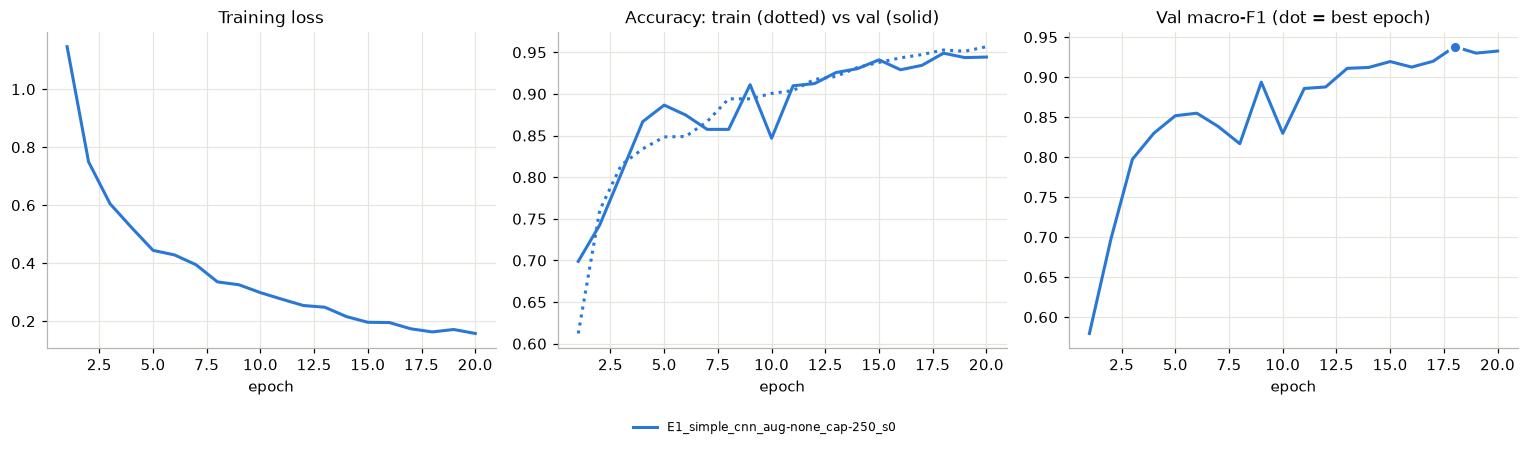

In [7]:
run_dirs = [d for d in sorted(RUNS.iterdir())
            if not d.name.startswith("debug_") and (d / "history.csv").exists()
            and (d / "history.csv").stat().st_size > 1]  # majority baseline has an empty history

if not run_dirs:
    print("No trained networks yet.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    for color, d in zip(RUN_COLORS, run_dirs):
        h = pd.read_csv(d / "history.csv")
        best = h.loc[h["val_macro_f1"].idxmax()]
        axes[0].plot(h["epoch"], h["train_loss"], color=color, linewidth=2, label=d.name)
        axes[1].plot(h["epoch"], h["train_acc"], color=color, linewidth=2, linestyle=":")
        axes[1].plot(h["epoch"], h["val_acc"], color=color, linewidth=2)
        axes[2].plot(h["epoch"], h["val_macro_f1"], color=color, linewidth=2)
        axes[2].plot(best["epoch"], best["val_macro_f1"], "o", color=color, markersize=8,
                     markeredgecolor="white", markeredgewidth=2)
    axes[0].set_title("Training loss")
    axes[1].set_title("Accuracy: train (dotted) vs val (solid)")
    axes[2].set_title("Val macro-F1 (dot = best epoch)")
    for ax in axes:
        ax.set_xlabel("epoch")
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=min(3, len(run_dirs)),
               fontsize=8, bbox_to_anchor=(0.5, -0.08))
    fig.tight_layout()
    fig.savefig(FIGURES / "training_curves.png", dpi=200, bbox_inches="tight")
    plt.show()

## 6. Per-class recall
Recall = of the images that truly are this disease, the fraction the model got right.
Comparing the two panels shows *which* diseases break down on field images.

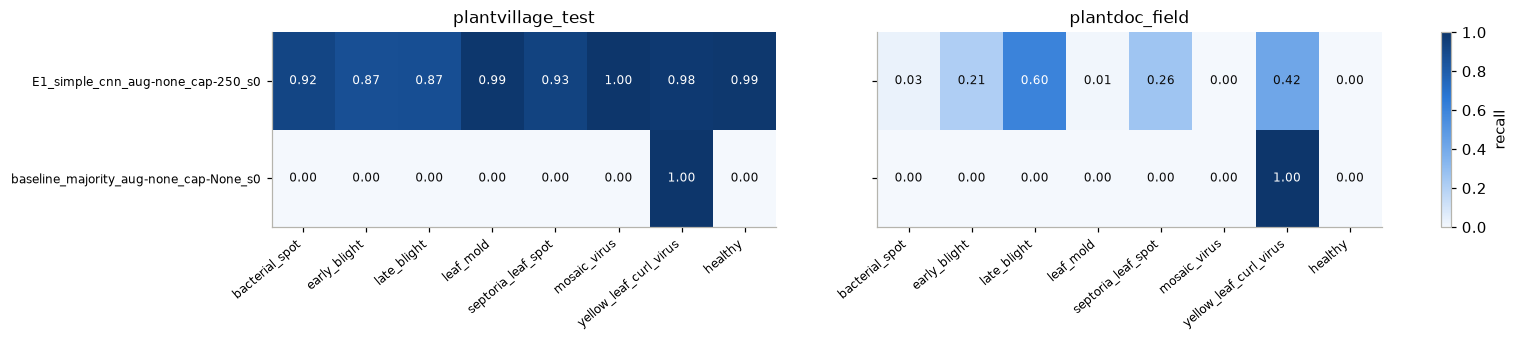

In [8]:
def recall_matrix(eval_set):
    rows = {}
    for d in sorted(RUNS.iterdir()):
        if d.name.startswith("debug_") or not (d / "metrics.json").exists():
            continue
        per_class = json.loads((d / "metrics.json").read_text())[eval_set]["per_class"]
        rows[d.name] = [per_class[label]["recall"] for label in LABELS]
    return pd.DataFrame.from_dict(rows, orient="index", columns=LABELS)

recalls = {s: recall_matrix(s) for s in ["plantvillage_test", "plantdoc_field"]}
n_runs = len(recalls["plantvillage_test"])
fig, axes = plt.subplots(1, 2, figsize=(14, 1.2 + 0.55 * n_runs), sharey=True)
for ax, (eval_set, m) in zip(axes, recalls.items()):
    im = ax.imshow(m.to_numpy(), cmap=BLUES, vmin=0, vmax=1, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.6 else "#0b0b0b")
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(m)), m.index, fontsize=8)
    ax.set_title(eval_set)
    ax.grid(False)
fig.colorbar(im, ax=axes, fraction=0.02, label="recall")
fig.savefig(FIGURES / "per_class_recall.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Confusion matrices for one run
Rows = true class, columns = predicted class; numbers are image counts, colour is the row percentage.
Change `RUN_NAME` to look at another run (names are printed below).

available runs:
  E1_simple_cnn_aug-none_cap-250_s0
  baseline_majority_aug-none_cap-None_s0

showing: E1_simple_cnn_aug-none_cap-250_s0


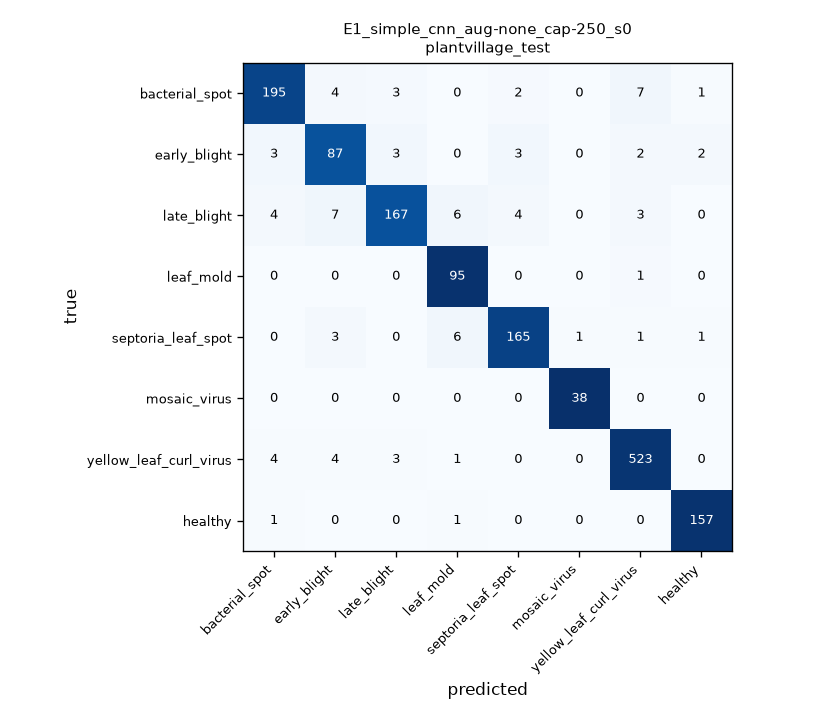

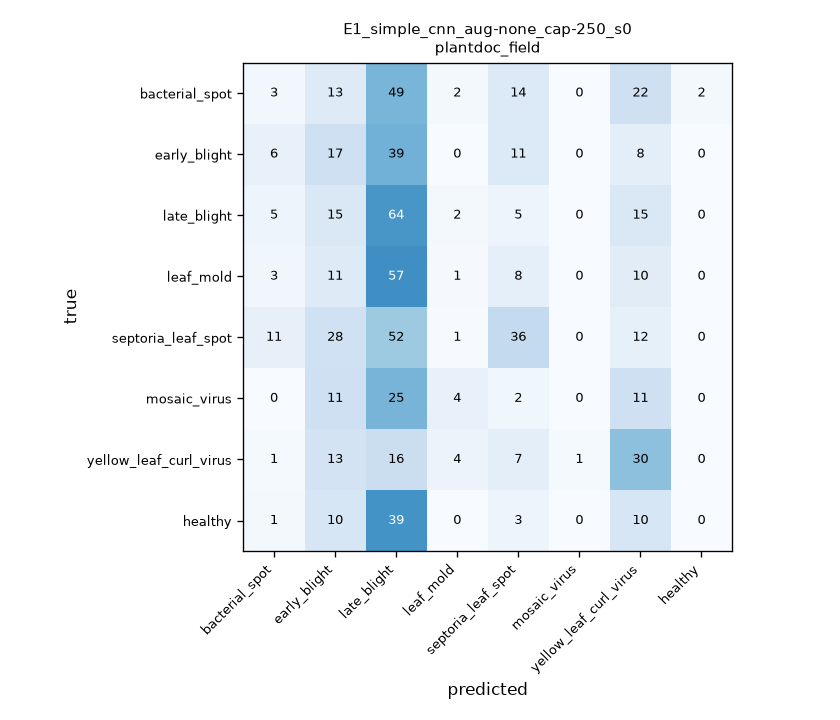

In [9]:
available = [d.name for d in sorted(RUNS.iterdir()) if not d.name.startswith("debug_")]
print("available runs:", *available, sep="\n  ")
RUN_NAME = next((n for n in available if not n.startswith("baseline")), available[0])  # first trained network
print("\nshowing:", RUN_NAME)
for eval_set in ["plantvillage_test", "plantdoc_field"]:
    display(Image(filename=str(RUNS / RUN_NAME / f"confusion_{eval_set}.png"), width=520))

## 8. Model cost
Parameter count and inference time per image (batch size 1) for the computational-cost comparison.
Inference time depends on the machine the run was evaluated on (shown in `device`).

In [10]:
cost = []
for d in sorted(RUNS.iterdir()):
    if d.name.startswith("debug_") or not (d / "metrics.json").exists():
        continue
    metrics = json.loads((d / "metrics.json").read_text())
    run = results[results["run_name"] == d.name].iloc[0]
    cost.append({"run": d.name, "params": int(run["params"]), "train time (min)": round(run["train_time_s"] / 60, 1),
                 "inference (ms/image)": round(metrics["inference_ms_per_image"], 2), "device": metrics["device"]})
pd.DataFrame(cost).set_index("run")

,params,train time (min),inference (ms/image),device
run,,,,
E1_simple_cnn_aug-none_cap-250_s0,390952,30.2,3.09,mps
baseline_majority_aug-none_cap-None_s0,0,0.0,0.00,mps
